In [ ]:
import os
os.environ["DEEPFACE_BACKEND_ENGINE"] = "onnx"

import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from retinaface import RetinaFace
from mtcnn import MTCNN

In [3]:
data = pd.read_csv("C:/DATA/face-detection/training.csv")
data.head()

,left_eye_center_x,left_eye_center_y,right_eye_center_x,right_eye_center_y,left_eye_inner_corner_x,left_eye_inner_corner_y,left_eye_outer_corner_x,left_eye_outer_corner_y,right_eye_inner_corner_x,right_eye_inner_corner_y,...,nose_tip_y,mouth_left_corner_x,mouth_left_corner_y,mouth_right_corner_x,mouth_right_corner_y,mouth_center_top_lip_x,mouth_center_top_lip_y,mouth_center_bottom_lip_x,mouth_center_bottom_lip_y,Image
0,66.033564,39.002274,30.227008,36.421678,59.582075,39.647423,73.130346,39.969997,36.356571,37.389402,...,57.066803,61.195308,79.970165,28.614496,77.388992,43.312602,72.935459,43.130707,84.485774,238 236 237 238 240 240 239 241 241 243 240 23...
1,64.332936,34.970077,29.949277,33.448715,58.856170,35.274349,70.722723,36.187166,36.034723,34.361532,...,55.660936,56.421447,76.352000,35.122383,76.047660,46.684596,70.266553,45.467915,85.480170,219 215 204 196 204 211 212 200 180 168 178 19...
2,65.057053,34.909642,30.903789,34.909642,59.412000,36.320968,70.984421,36.320968,37.678105,36.320968,...,53.538947,60.822947,73.014316,33.726316,72.732000,47.274947,70.191789,47.274947,78.659368,144 142 159 180 188 188 184 180 167 132 84 59 ...
3,65.225739,37.261774,32.023096,37.261774,60.003339,39.127179,72.314713,38.380967,37.618643,38.754115,...,54.166539,65.598887,72.703722,37.245496,74.195478,50.303165,70.091687,51.561183,78.268383,193 192 193 194 194 194 193 192 168 111 50 12 ...
4,66.725301,39.621261,32.244810,38.042032,58.565890,39.621261,72.515926,39.884466,36.982380,39.094852,...,64.889521,60.671411,77.523239,31.191755,76.997301,44.962748,73.707387,44.227141,86.871166,147 148 160 196 215 214 216 217 219 220 206 18...


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7049 entries, 0 to 7048
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   left_eye_center_x          7039 non-null   float64
 1   left_eye_center_y          7039 non-null   float64
 2   right_eye_center_x         7036 non-null   float64
 3   right_eye_center_y         7036 non-null   float64
 4   left_eye_inner_corner_x    2271 non-null   float64
 5   left_eye_inner_corner_y    2271 non-null   float64
 6   left_eye_outer_corner_x    2267 non-null   float64
 7   left_eye_outer_corner_y    2267 non-null   float64
 8   right_eye_inner_corner_x   2268 non-null   float64
 9   right_eye_inner_corner_y   2268 non-null   float64
 10  right_eye_outer_corner_x   2268 non-null   float64
 11  right_eye_outer_corner_y   2268 non-null   float64
 12  left_eyebrow_inner_end_x   2270 non-null   float64
 13  left_eyebrow_inner_end_y   2270 non-null   float64
 14  lef

In [5]:
# Thống kê số nhãn bị thiếu
missing = data.isnull().sum().sort_values(ascending=False)

display(missing[missing > 0])
print("Total images:", len(data))
print("Images with all labels:", data.dropna().shape[0])

left_eyebrow_outer_end_x     4824
left_eyebrow_outer_end_y     4824
right_eyebrow_outer_end_x    4813
right_eyebrow_outer_end_y    4813
left_eye_outer_corner_y      4782
left_eye_outer_corner_x      4782
right_eye_inner_corner_x     4781
right_eye_outer_corner_y     4781
right_eye_inner_corner_y     4781
right_eye_outer_corner_x     4781
mouth_left_corner_x          4780
mouth_left_corner_y          4780
left_eyebrow_inner_end_x     4779
right_eyebrow_inner_end_y    4779
left_eyebrow_inner_end_y     4779
mouth_right_corner_y         4779
right_eyebrow_inner_end_x    4779
mouth_right_corner_x         4779
left_eye_inner_corner_y      4778
left_eye_inner_corner_x      4778
mouth_center_top_lip_x       4774
mouth_center_top_lip_y       4774
mouth_center_bottom_lip_x      33
mouth_center_bottom_lip_y      33
right_eye_center_y             13
right_eye_center_x             13
left_eye_center_x              10
left_eye_center_y              10
dtype: int64

Total images: 7049
Images with all labels: 2140


In [6]:
# Các landmark cần đánh giá
KEYPOINTS = [
    "left_eye_center",
    "right_eye_center",
    "nose_tip",
    "mouth_left_corner",
    "mouth_right_corner"
]

COORD_COLUMNS = [
    f"{point}_{axis}"
    for point in KEYPOINTS
    for axis in ("x", "y")
]

# Chỉ giữ ảnh có đủ nhãn cho cả 5 landmark
valid_data = data.dropna(subset=COORD_COLUMNS + ["Image"]).copy()

print("Valid images:", len(valid_data))
print("Excluded images:", len(data) - len(valid_data))

Valid images: 2250
Excluded images: 4799


In [7]:
# Chuyển dữ liệu pixel thành ảnh NumPy
def parse_image(pixel_string):
    pixels = np.fromstring(pixel_string, sep=" ", dtype=np.uint8)

    if pixels.size != 96 * 96:
        raise ValueError(f"Expected 9216 pixels, got {pixels.size}")

    return pixels.reshape(96, 96)


images = np.stack([
    parse_image(pixel_string)
    for pixel_string in valid_data["Image"]
])

# Ground truth: mỗi ảnh có 5 điểm, mỗi điểm gồm x và y
ground_truth = valid_data[COORD_COLUMNS].to_numpy(
    dtype=np.float32
).reshape(-1, 5, 2)

print("Images shape:", images.shape)
print("Ground truth shape:", ground_truth.shape)

Images shape: (2250, 96, 96)
Ground truth shape: (2250, 5, 2)


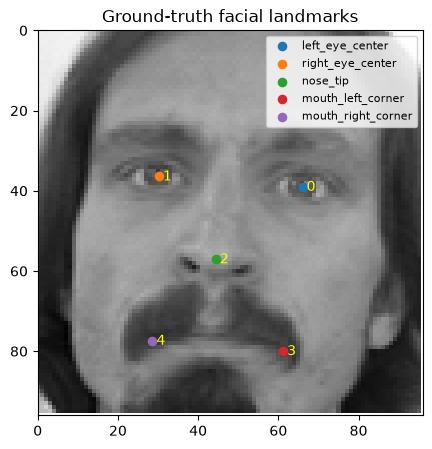

In [8]:
# Hiển thị một ảnh và 5 landmark ground truth
idx = 0

plt.figure(figsize=(5, 5))
plt.imshow(images[idx], cmap="gray")

for i, (x, y) in enumerate(ground_truth[idx]):
    plt.scatter(x, y, s=35, label=KEYPOINTS[i])
    plt.text(x + 1, y + 1, str(i), color="yellow", fontsize=10)

plt.xlim(0, 96)
plt.ylim(96, 0)
plt.title("Ground-truth facial landmarks")
plt.legend(fontsize=8)
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# Giữ nguyên index để truy xuất nhãn tương ứng
all_indices = np.arange(len(images))

_, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42
)

# Giới hạn số ảnh để chạy thử ban đầu
MAX_VAL_IMAGES = 500
val_indices = val_indices[:MAX_VAL_IMAGES]

val_images = images[val_indices]
val_ground_truth = ground_truth[val_indices]

print("Validation images:", len(val_images))

Validation images: 450


# Khởi tạo mô hình

In [10]:
class FaceLandmarkDetector:
    def __init__(self, model_path):
        base_options = mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        )

        options = mp.tasks.vision.FaceLandmarkerOptions(
            base_options=base_options,
            running_mode=mp.tasks.vision.RunningMode.IMAGE,
            num_faces=1,
            min_face_detection_confidence=0.5,
            min_face_presence_confidence=0.5,
            min_tracking_confidence=0.5
        )

        self.landmarker = (
            mp.tasks.vision.FaceLandmarker
            .create_from_options(options)
        )

        self.timestamp_ms = 0

    def process(self, frame):
        # OpenCV dùng BGR → chuyển sang RGB
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # Chuyển ảnh sang MediaPipe Image
        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        # Timestamp phải tăng dần
        self.timestamp_ms += 33

        # Phát hiện khuôn mặt + landmarks
        result = self.landmarker.detect_for_video(
            image,
            self.timestamp_ms
        )

        return result.face_landmarks

    def close(self):
        self.landmarker.close()

In [24]:
class RetinaFaceDetector:
    def __init__(self):
        # RetinaFace tự tải hoặc nạp weights qua thư viện
        pass

    def process(self, frame):
        # OpenCV BGR -> RGB
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Phát hiện khuôn mặt và 5 facial landmarks
        result = RetinaFace.detect_faces(rgb_frame)

        if not isinstance(result, dict) or not result:
            return []

        # Chọn khuôn mặt có bounding box lớn nhất
        face = max(
            result.values(),
            key=lambda item: (
                item["facial_area"][2] - item["facial_area"][0]
            ) * (
                item["facial_area"][3] - item["facial_area"][1]
            )
        )

        return face.get("landmarks", {})

In [12]:
class MTCNNDetector:
    def __init__(self):
        # Khởi tạo model một lần, không tạo lại ở mỗi ảnh
        self.detector = MTCNN()

    def process(self, frame):
        # OpenCV BGR -> RGB
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Phát hiện khuôn mặt và 5 facial landmarks
        faces = self.detector.detect_faces(rgb_frame)

        if not faces:
            return []

        # Chọn khuôn mặt có bounding box lớn nhất
        face = max(
            faces,
            key=lambda item: item["box"][2] * item["box"][3]
        )

        return face.get("keypoints", {})

In [25]:
TASK_PATH = "../face_landmarker.task"

mediapipe_detector = FaceLandmarkDetector(TASK_PATH)
retinaface_detector = RetinaFaceDetector()
mtcnn_detector = MTCNNDetector()

In [14]:
# MediaPipe Face Landmarker đã được khởi tạo ở cell trước
# RetinaFace và MTCNN cũng cần import thành công

def prepare_image(gray):
    """Chuyển ảnh grayscale 96x96 thành RGB 192x192."""
    enlarged = cv2.resize(
        gray, (192, 192),
        interpolation=cv2.INTER_CUBIC
    )
    return cv2.cvtColor(enlarged, cv2.COLOR_GRAY2RGB)


def sort_by_x(points):
    """Sắp xếp landmark từ trái sang phải theo ảnh."""
    points = np.asarray(points, dtype=np.float32)
    return points[np.argsort(points[:, 0])]

# Benchmark mô hình

In [15]:
def mediapipe_predict(rgb):
    """Ánh xạ Face Mesh thành 5 điểm trên ảnh gốc 96x96."""
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    # Model đang chạy ở IMAGE mode nên gọi detect()
    result = mediapipe_detector.landmarker.detect(mp_image)

    if not result.face_landmarks:
        return None

    lm = result.face_landmarks[0]

    def point(index):
        return np.array(
            [lm[index].x * 192, lm[index].y * 192],
            dtype=np.float32
        )

    # Ước lượng tâm mắt bằng trung điểm hai góc mắt
    eyes = sort_by_x([
        (point(33) + point(133)) / 2,
        (point(362) + point(263)) / 2
    ])

    # Chóp mũi và hai khóe miệng
    mouth = sort_by_x([point(61), point(291)])
    nose = point(1)

    # 192x192 -> 96x96
    return np.array(
        [eyes[0], eyes[1], nose, mouth[0], mouth[1]]
    ) / 2

In [28]:
def retinaface_predict(rgb):
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    result = RetinaFace.detect_faces(bgr, threshold=0.7)

    if not isinstance(result, dict) or not result:
        return None

    face = max(
        result.values(),
        key=lambda item: (
            item["facial_area"][2] - item["facial_area"][0]
        ) * (
            item["facial_area"][3] - item["facial_area"][1]
        )
    )

    lm = face["landmarks"]

    # Sắp xếp các điểm theo tọa độ x để thống nhất thứ tự
    eyes = sort_by_x([lm["left_eye"], lm["right_eye"]])
    mouth = sort_by_x([lm["mouth_left"], lm["mouth_right"]])

    points = np.array(
        [eyes[0], eyes[1], lm["nose"], mouth[0], mouth[1]],
        dtype=np.float32
    )

    return points / 2.0

In [ ]:
def mtcnn_predict(rgb):
    """Lấy 5 landmark từ MTCNN."""
    faces = mtcnn_detector.detector.detect_faces(rgb)

    if not faces:
        return None

    face = max(
        faces,
        key=lambda item: item["box"][2] * item["box"][3]
    )

    lm = face.get("keypoints", {})
    required = [
        "left_eye", "right_eye", "nose",
        "mouth_left", "mouth_right"
    ]

    if not all(key in lm for key in required):
        return None

    eyes = sort_by_x([lm["left_eye"], lm["right_eye"]])
    mouth = sort_by_x([lm["mouth_left"], lm["mouth_right"]])

    points = np.array(
        [eyes[0], eyes[1], lm["nose"], mouth[0], mouth[1]],
        dtype=np.float32
    )

    return points / 2

In [29]:
rgb = prepare_image(val_images[0])

for name, predict_fn in {
    "MediaPipe": mediapipe_predict,
    "RetinaFace": retinaface_predict,
    "MTCNN": mtcnn_predict
}.items():
    try:
        pred = predict_fn(rgb)
        print(name, ":", None if pred is None else pred.shape)
    except Exception as e:
        print(name, "ERROR:", repr(e))

MediaPipe : (5, 2)
RetinaFace : (5, 2)
MTCNN : (5, 2)


# Kết quả

In [30]:
import time

predictors = {
    "MediaPipe": mediapipe_predict,
    "RetinaFace": retinaface_predict,
    "MTCNN": mtcnn_predict
}

benchmark_results = {}

for model_name, predict_fn in predictors.items():
    predictions = []
    elapsed_times = []
    errors = []

    print(f"Running {model_name}...")

    for i, gray in enumerate(val_images):
        rgb = prepare_image(gray)

        start = time.perf_counter()

        try:
            pred = predict_fn(rgb)
        except Exception as exc:
            pred = None
            errors.append((i, str(exc)))

        elapsed = time.perf_counter() - start
        elapsed_times.append(elapsed)

        predictions.append(pred)

        if (i + 1) % 50 == 0:
            print(f"  Processed {i + 1}/{len(val_images)}")

    benchmark_results[model_name] = {
        "predictions": predictions,
        "times": np.array(elapsed_times),
        "errors": errors
    }

    detected = sum(p is not None for p in predictions)

    print(
        f"{model_name}: {detected}/{len(val_images)} "
        f"faces detected; {len(errors)} errors"
    )

print("Inference finished.")

Running MediaPipe...
  Processed 50/450
  Processed 100/450
  Processed 150/450
  Processed 200/450
  Processed 250/450
  Processed 300/450
  Processed 350/450
  Processed 400/450
  Processed 450/450
MediaPipe: 450/450 faces detected; 0 errors
Running RetinaFace...
  Processed 50/450
  Processed 100/450
  Processed 150/450
  Processed 200/450
  Processed 250/450
  Processed 300/450
  Processed 350/450
  Processed 400/450
  Processed 450/450
RetinaFace: 83/450 faces detected; 0 errors
Running MTCNN...
  Processed 50/450
  Processed 100/450
  Processed 150/450
  Processed 200/450
  Processed 250/450
  Processed 300/450
  Processed 350/450
  Processed 400/450
  Processed 450/450
MTCNN: 421/450 faces detected; 0 errors
Inference finished.


In [31]:
summary = []

for model_name, result in benchmark_results.items():
    predictions = result["predictions"]
    times = result["times"]

    valid_errors = []

    for pred, gt in zip(predictions, val_ground_truth):
        if pred is None:
            continue

        # Khoảng cách giữa hai tâm mắt ground truth
        interocular = np.linalg.norm(gt[0] - gt[1])

        if interocular <= 0:
            continue

        point_errors = np.linalg.norm(pred - gt, axis=1)
        nme = np.mean(point_errors) / interocular
        valid_errors.append(nme)

    detected = sum(p is not None for p in predictions)

    summary.append({
        "Model": model_name,
        "Detection rate (%)": 100 * detected / len(val_images),
        "NME (%)": (
            100 * np.mean(valid_errors)
            if valid_errors else np.nan
        ),
        "Mean inference (ms)": 1000 * np.mean(times),
        "FPS (inference only)": (
            1 / np.mean(times) if np.mean(times) > 0 else np.nan
        ),
        "Errors": len(result["errors"])
    })

summary_df = pd.DataFrame(summary)
display(summary_df.sort_values("NME (%)"))

,Model,Detection rate (%),NME (%),Mean inference (ms),FPS (inference only),Errors
1,RetinaFace,18.444444,70.699463,721.918154,1.385199,0
0,MediaPipe,100.000000,73.271957,8.081668,123.736839,0
2,MTCNN,93.555556,74.096085,131.673610,7.594536,0


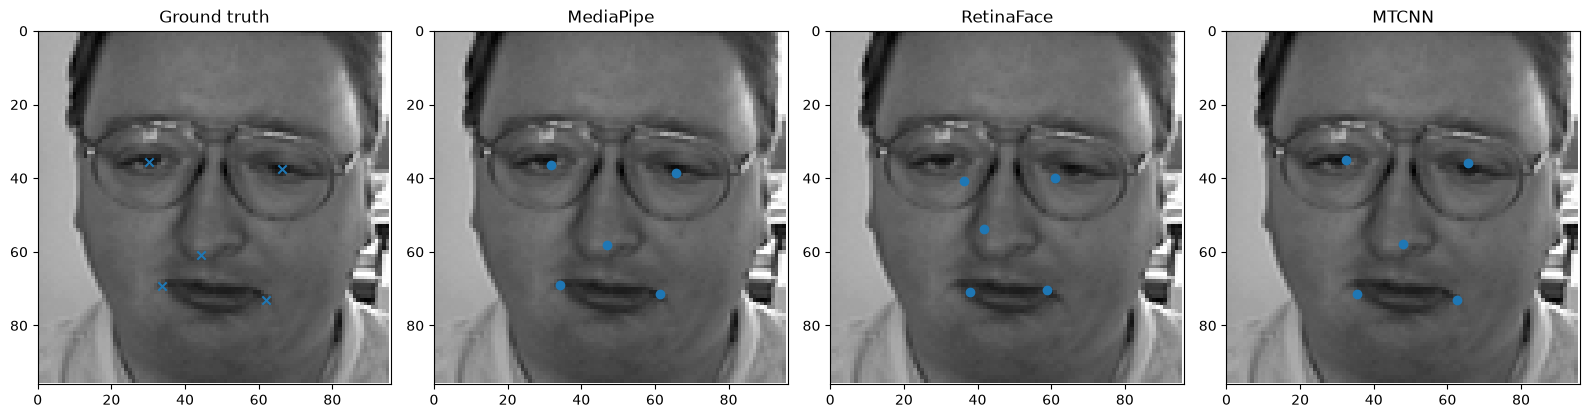

In [32]:
def visualize_predictions(index):
    gray = val_images[index]
    gt = val_ground_truth[index]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(gray, cmap="gray")
    axes[0].scatter(gt[:, 0], gt[:, 1], marker="x")
    axes[0].set_title("Ground truth")

    for ax, (model_name, result) in zip(
        axes[1:], benchmark_results.items()
    ):
        ax.imshow(gray, cmap="gray")

        pred = result["predictions"][index]

        if pred is not None:
            ax.scatter(pred[:, 0], pred[:, 1], marker="o")
        else:
            ax.text(
                0.5, 0.5, "No detection",
                transform=ax.transAxes,
                ha="center"
            )

        ax.set_title(model_name)

    for ax in axes:
        ax.set_xlim(0, 96)
        ax.set_ylim(96, 0)

    plt.tight_layout()
    plt.show()


visualize_predictions(0)